In [25]:
# CSDS 513 - Final Project
# Effect of Learning Rates on Gradient Descent

import numpy as np
import matplotlib.pyplot as plt

In [26]:
# Generate synthetic dataset

np.random.seed(42)

n = 100

# Generate 100 random observations
x = np.random.randn(n)

# Generate random noise
noise = np.random.normal(0, 0.5, n)

# True relationship: y = 3 + 2x + noise
y = 3 + 2 * x + noise

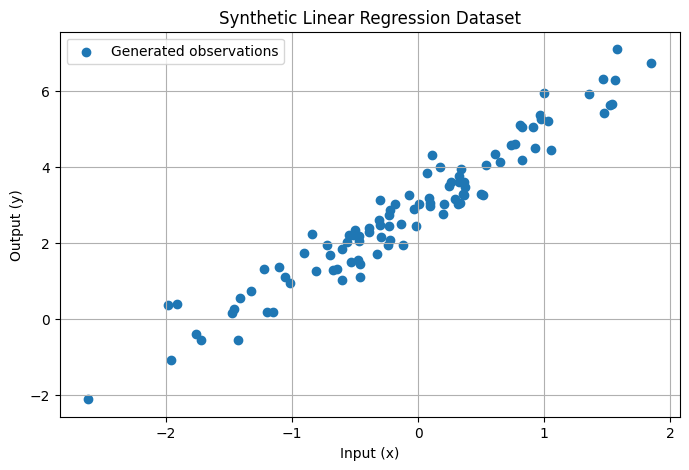

In [27]:
# Visualize the synthetic dataset

plt.figure(figsize=(8, 5))

plt.scatter(x, y, label="Generated observations")

plt.xlabel("Input (x)")
plt.ylabel("Output (y)")
plt.title("Synthetic Linear Regression Dataset")

plt.legend()
plt.grid(True)
plt.show()

In [28]:
# Construct the design matrix

X = np.column_stack((np.ones(n), x))

In [29]:
# Calculate the largest eigenvalue

H = (X.T @ X) / n

eigenvalues = np.linalg.eigvalsh(H)

L = eigenvalues.max()

print("Eigenvalues:", eigenvalues)
print("Largest eigenvalue (L):", L)
print("Maximum theoretical learning rate:", 2 / L)

Eigenvalues: [0.77859805 1.04870824]
Largest eigenvalue (L): 1.0487082401712389
Maximum theoretical learning rate: 1.9071081196743804


In [30]:
# Gradient descent implementation

def gradient_descent(X, y, alpha, iterations=300):

    n = len(y)

    # Initialize parameters
    theta = np.zeros(X.shape[1])

    # Store objective values
    losses = []

    for i in range(iterations + 1):

        # Predictions
        predictions = X @ theta

        # Errors
        errors = predictions - y

        # Objective function
        loss = np.sum(errors ** 2) / (2 * n)

        losses.append(loss)

        # Stop after recording the final objective
        if i == iterations:
            break

        # Calculate gradient
        gradient = (X.T @ errors) / n

        # Update parameters
        theta = theta - alpha * gradient

    return theta, losses

In [31]:
# Define three learning rates

learning_rates = {
    "Small": 0.05 / L,
    "Moderate": 0.5 / L,
    "Large": 1.0 / L
}

# Store experimental results

results = {}

for name, alpha in learning_rates.items():

    theta, losses = gradient_descent(
        X, y, alpha, iterations=300
    )

    results[name] = {
        "learning_rate": alpha,
        "parameters": theta,
        "losses": losses
    }

    print("\nExperiment:", name)
    print("Learning rate:", alpha)
    print("Estimated intercept:", theta[0])
    print("Estimated slope:", theta[1])
    print("Final objective:", losses[-1])


Experiment: Small
Learning rate: 0.047677702991859514
Estimated intercept: 3.0036984344686433
Estimated slope: 1.928339344160567
Final objective: 0.11045406078025609

Experiment: Moderate
Learning rate: 0.4767770299185951
Estimated intercept: 3.0037139149319834
Estimated slope: 1.928371419864278
Final objective: 0.11045406028641105

Experiment: Large
Learning rate: 0.9535540598371902
Estimated intercept: 3.0037139149319834
Estimated slope: 1.9283714198642783
Final objective: 0.11045406028641104


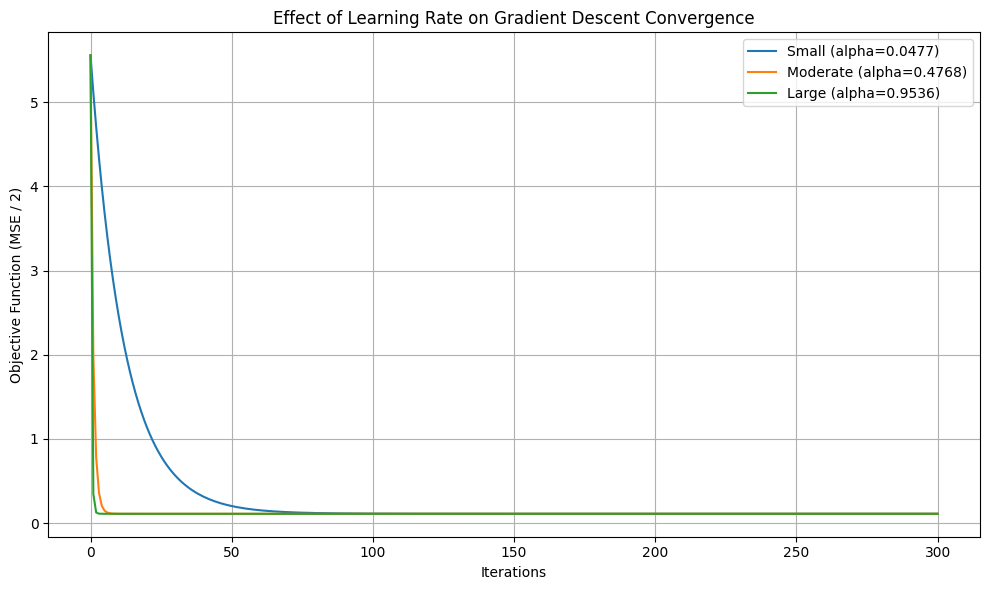

In [32]:
# Compare convergence behavior

plt.figure(figsize=(10, 6))

for name, result in results.items():

    plt.plot(
        result["losses"],
        label=f"{name} (alpha={result['learning_rate']:.4f})"
    )

plt.xlabel("Iterations")
plt.ylabel("Objective Function (MSE / 2)")
plt.title("Effect of Learning Rate on Gradient Descent Convergence")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig("convergence_plot.png", dpi=300)

plt.show()

In [33]:
# Calculate the least-squares reference solution

theta_optimal = np.linalg.lstsq(X, y, rcond=None)[0]

optimal_loss = np.sum((X @ theta_optimal - y) ** 2) / (2 * n)

print("Least-squares reference solution")
print("Intercept:", theta_optimal[0])
print("Slope:", theta_optimal[1])
print("Minimum objective:", optimal_loss)

print("\nEXPERIMENTAL RESULTS")
print("-" * 85)
print(f"{'Method':<12} {'Intercept':>12} {'Slope':>12} {'Final Loss':>15} {'Iterations':>12}")
print("-" * 85)

for name, result in results.items():

    theta = result["parameters"]

    print(
        f"{name:<12} "
        f"{theta[0]:>12.6f} "
        f"{theta[1]:>12.6f} "
        f"{result['losses'][-1]:>15.8f} "
        f"{len(result['losses']) - 1:>12}"
    )

print("-" * 85)

Least-squares reference solution
Intercept: 3.0037139149319834
Slope: 1.9283714198642778
Minimum objective: 0.11045406028641104

EXPERIMENTAL RESULTS
-------------------------------------------------------------------------------------
Method          Intercept        Slope      Final Loss   Iterations
-------------------------------------------------------------------------------------
Small            3.003698     1.928339      0.11045406          300
Moderate         3.003714     1.928371      0.11045406          300
Large            3.003714     1.928371      0.11045406          300
-------------------------------------------------------------------------------------


In [34]:
# Calculate iterations needed to reach convergence tolerance

tolerance = 1e-6

print("CONVERGENCE SPEED COMPARISON")
print("-" * 55)

for name, result in results.items():

    losses = np.array(result["losses"])

    differences = losses - optimal_loss

    converged = np.where(differences < tolerance)[0]

    if len(converged) > 0:
        iteration = converged[0]
        print(f"{name}: {iteration} iterations")
    else:
        print(f"{name}: Tolerance not reached")

print("-" * 55)

CONVERGENCE SPEED COMPARISON
-------------------------------------------------------
Small: 200 iterations
Moderate: 17 iterations
Large: 6 iterations
-------------------------------------------------------
